# Multiparity calibration and central-boson population measurements

Run the acquisition cells you need. Each runner returns the measured Experiment;
its analyze() calculates the multiparity results before the worker saves the JOB.
Pass the calibration HDF5 filename so corrected populations and moments are saved
with each measurement. Plot the saved results directly.

One calibration JOB prepares Fock 0..3. Each FockPopulationExperiment JOB measures
one occupation and read mode over cycles. AGP classes orchestrate those JOBs from
this notebook and assemble their moments into C1/C2; they do not run on the worker.
Assembled HDF5s contain their own arrays, with manifests pointing to the layer below.
ro_stor=0 selects M1; positive values are physical storage IDs.

In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from slab import AttrDict

from experiments import CharacterizationRunner, MultimodeStation
from experiments.qsim.agp import CentralBosonAGPDisorderScan
from experiments.qsim.fock_population import FockPopulationExperiment
from experiments.qsim.multiparity_confusion_matrix import MultiParityConfusionMatrixExperiment
from experiments.qsim.notebook_helpers.defaults import ACTIVE_RESET_DEFAULTS, FLOQUET_DEFAULTS
from fitting.qsim.mbr_hamiltonian import fixed_n_hamiltonian
from job_server import JobClient

Importing all classes from  C:\python\multimode_expts\experiments\autocal
Importing all classes from  C:\python\multimode_expts\experiments\dual_rail
Importing all classes from  C:\python\multimode_expts\experiments\qsim
Importing all classes from  C:\python\multimode_expts\experiments\qubit_cavity
Importing all classes from  C:\python\multimode_expts\experiments\single_qubit
Importing all classes from  C:\python\multimode_expts\experiments\transduction
Skipped top-level files ['assembled_data.py', 'branch_manager.py', 'characterization_runner.py', 'dataset.py', 'floquet_timing.py', 'job_paths.py', 'local_env.py', 'MM_base.py', 'MM_dual_rail_base.py', 'MM_rb_base.py', 'mock_hardware.py', 'readout_calibration.py', 'sequential_experiment.py', 'sequential_experiment_classes.py', 'station.py', 'sweep_runner.py']


## 1. Station and worker

These are the configuration versions used by the existing measurement notebook.
Constructing the runners below does not submit measurements.

In [2]:
user = "jonginn"
config_dict = {'hardware_config': 'CFG-HW-20261023-00038',
 'multiphoton_config': 'CFG-MP-20260121-00001',
 'man1_storage_swap': 'CFG-M1-20261023-00003',
 'floquet_storage_swap': 'CFG-FL-20261023-00002'}

client = JobClient()
health = client.health_check()
print(f"Server status: {health['status']}")
client.print_queue()

station = MultimodeStation(
    user=user,
    experiment_name="agp_k44_first_scan",
    project="AGP",
    log_measurements=True,
    hardware_config=config_dict["hardware_config"],
    multiphoton_config=config_dict["multiphoton_config"],
    storage_man_file=config_dict["man1_storage_swap"],
    floquet_file=config_dict["floquet_storage_swap"],
)

Server status: healthy

=== Job Queue ===

Running: JOB-20261023-00510
  User: seb
  Experiment: WignerTomography1ModeExperiment
  Started: 2026-10-23T21:14:39.027405

Pending: 2 jobs
  1. JOB-20261023-00511 - WignerTomography1ModeExperiment (user: seb, priority: 0)
  2. JOB-20261023-00512 - ErrorAmplification2DExperiment (user: seb, priority: 0)

[STATION] Using hardware_config version: CFG-HW-20261023-00038
[STATION] Using multiphoton_config version: CFG-MP-20260121-00001
[STATION] Using man1_storage_swap version: CFG-M1-20261023-00003
[STATION] Using floquet_storage_swap version: CFG-FL-20261023-00002
[STATION] Lab-notebook vault: G:\Shared drives\SLab\Multimode
Data, plots, logs will be stored in: C:\experiments\agp_k44_first_scan
Hardware configs will be read from C:\python\multimode_expts\configs\versions\hardware_config\CFG-HW-20261023-00038.yml
dict_keys(['Pyro.NameServer', 'Qick101'])
QICK running on ZCU216, software version 0.2.291

Firmware configuration (built Tue Oct 15 12

In [3]:
STORAGE_MODES = [4, 5, 6, 7]
common_defaults = AttrDict(dict(
    expts=1, reps=1, rounds=1, qubits=[0], f0g1_cavity=1,
    normalize=False, active_reset=True, man_reset=True,
    storage_reset=STORAGE_MODES, pre_relax_delay=100, relax_delay=200,
    postpulse=True, init_fock=False, init_stor=0, ro_stor=0,
    readout="multiparity", parity_fast=False,
    cond_sec_phase=-90, phase_second_pulse=180,
    swap_stors=STORAGE_MODES, update_phases=True,
    detunings=[0.0, 0.0, 0.0, 0.0],
))
common_defaults.update(ACTIVE_RESET_DEFAULTS)
common_defaults.update(FLOQUET_DEFAULTS)

# Calibration uses Qsim's prepulse; FockPopulationProgram prepares in core_pulses.
calibration_defaults = AttrDict(dict(common_defaults, prepulse=True))
population_defaults = AttrDict(dict(
    common_defaults, prepulse=False, occupations=[3, 0, 0, 0, 0],
    floquet_cycles=[0], swept_params=["floquet_cycle"],
))

In [4]:
confusion_matrix_runner = CharacterizationRunner(
    station=station,
    ExptClass=MultiParityConfusionMatrixExperiment,
    default_expt_cfg=calibration_defaults,
    job_client=client,
    use_queue=True,
    show=False,
)

population_runner = CharacterizationRunner(
    station=station,
    ExptClass=FockPopulationExperiment,
    default_expt_cfg=population_defaults,
    job_client=client,
    use_queue=True,
    show=False,
)

## 2. Fock 0..3 readout calibration: one JOB

The Experiment owns the prepared-state sweep and stores C[prepared, measured]
in data["multiparity_confusion_matrix"]. No additional population JOBs or
manual matrix construction are needed.

In [5]:
calibration_expt = confusion_matrix_runner.execute(reps=6000, postprocess=False)
print(calibration_expt.fname)

Job submitted: JOB-20261023-00513 (queue position: 3)

[0.0s] Job JOB-20261023-00513: pending

[752.4s] Job JOB-20261023-00513: running
[WORKER] Loading MultiParityConfusionMatrixExperiment from experiments.qsim.multiparity_confusion_matrix
[WORKER] Creating experiment instance
[WORKER]   Data file: JOB-20261023-00513_MultiParityConfusionMatrixExperiment.h5
[WORKER] Running experiment...
[WORKER] Setting coupler yoko current to 0.25mA according to hardware_cfg yaml...
[WORKER] Done setting coupler current
 75%|█████████████████████████████████           | 3/4 [00:15<00:05,  5.22s/it]
[774.5s] Job JOB-20261023-00513: completed
100%|████████████████████████████████████████████| 4/4 [00:20<00:00,  5.22s/it]
Saving C:\experiments\agp_k44_first_scan\data\JOB-20261023-00513_MultiParityConfusionMatrixExperiment.h5
[WORKER] Saving expt object to: C:\experiments\agp_k44_first_scan\expt_objs\JOB-20261023-00513_expt.pkl

Job completed! Data: C:\experiments\agp_k44_first_scan\data\JOB-20261023-005

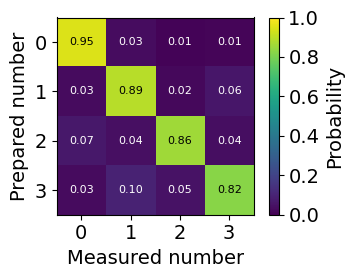

Confusion matrix condition number: 1.315104238741968


In [6]:
calibration_expt.display()
print("Confusion matrix condition number:",
      np.linalg.cond(calibration_expt.data["multiparity_confusion_matrix"]))

In [7]:
CONFUSION_MATRIX_FNAME = str(calibration_expt.fname)
# To reuse a saved calibration, replace the assignment above with its full HDF5 filename.

## 3. Population evolution from one initial occupation

Each measured mode uses a fresh preparation and a separate JOB. The worker
saves raw and corrected populations, mean n mod 4, and shot errors through
FockPopulationExperiment.analyze(). postpulse=True swaps the selected storage
into M1 before readout.

In [ ]:
swap_stors = list(STORAGE_MODES)
meas_stors = [0] + swap_stors
occupations = [3, 0, 0, 0, 0]
detunings = [0.0, 0.0, 0.0, 0.0]  # MHz
floquet_cycles = list(range(0, 100, 2))

Job submitted: JOB-20261019-00137 (queue position: 1)

[15.6s] Job JOB-20261019-00137: pending

[126.6s] Job JOB-20261019-00137: running
[WORKER] Loading QsimExperiment from experiments.qsim.qsim_base
[WORKER] Creating experiment instance
[WORKER]   Data file: JOB-20261019-00137_QsimExperiment.h5
[WORKER]   Program: FockPopulationProgram from experiments.qsim.fock_population
[WORKER] Running experiment...
[WORKER] Setting coupler yoko current to 0.25mA according to hardware_cfg yaml...
[WORKER] Done setting coupler current
 88%|████████████████████████████████████▉     | 44/50 [00:19<00:02,  2.24it/s]

In [ ]:
walk_expts = []
for meas_stor in meas_stors:
    walk_expt = population_runner.execute(
        reps=300,
        occupations=occupations,
        swap_stors=swap_stors,
        storage_reset=swap_stors,
        ro_stor=meas_stor,
        detunings=detunings,
        floquet_cycles=floquet_cycles,
        multiparity_confusion_matrix=CONFUSION_MATRIX_FNAME,
        postprocess=False, show=False, log=False,
    )
    walk_expts.append(walk_expt)
    print(walk_expt.fname)

In [ ]:
walk_fig, walk_axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
for walk_expt in walk_expts:
    data = walk_expt.data
    mode = walk_expt.cfg.expt.ro_stor
    walk_axes[0].plot(data["xpts"], data["nmod4_mean"], label=f"Raw, Mode {mode}")
    walk_axes[1].plot(data["xpts"], data["nmod4_mean_corrected"],
                      label=f"Corrected, Mode {mode}")
for axis in walk_axes:
    axis.set(xlabel="Floquet cycles", ylabel="Mean n mod 4")
    axis.legend()
walk_fig.tight_layout()
plt.show()

### Optional: compare population evolution with the fixed-N Hamiltonian

Use each JOB's recorded Floquet timing and couplings. The physical Kerr is
supplied separately. This comparison uses H/h in MHz with onsite storage
energies -detuning. For the N=3 input above, number and number modulo 4 agree.

In [ ]:
KERR_KHZ = -27.0  # K / (2*pi), including its sign.

In [ ]:
theory_axis = walk_axes[1]
for line in list(theory_axis.lines):
    if line.get_label().startswith("Theory,"):
        line.remove()
measured_colors = {line.get_label(): line.get_color() for line in theory_axis.lines}

for plot_index, walk_expt in enumerate(walk_expts):
    settings = walk_expt.cfg.expt
    storages = list(settings.swap_stors)
    initial_occupation = tuple(settings.occupations)
    readout_storage = settings.ro_stor
    readout_index = [0, *storages].index(readout_storage)
    timing = walk_expt.recorded_derived_params()
    cycle_us = float(timing["floquet_cycle_us"])
    couplings_mhz = np.array([timing["couplings_MHz"][storage - 1] for storage in storages])
    if settings.get("zero_floquet_gain", False):
        couplings_mhz[:] = 0.0
    detunings_mhz = settings.get("detunings")
    if detunings_mhz is None or detunings_mhz is False or len(detunings_mhz) == 0:
        detunings_mhz = np.zeros(len(storages))

    model = fixed_n_hamiltonian(
        photon_number=sum(initial_occupation),
        mode_count=1 + len(storages),
        detunings=detunings_mhz,
        couplings_MHz=couplings_mhz,
        physical_kerr_MHz=KERR_KHZ / 1000,
    )
    cycles = np.asarray(walk_expt.data["xpts"], dtype=float)
    theory_cycles = np.linspace(cycles.min(), cycles.max(), max(1000, len(cycles)))
    time_us = theory_cycles * cycle_us
    initial_index = model.fock_index[initial_occupation]
    eigenstate_amplitudes = model.states[initial_index, :].conj()
    phases = np.exp(-2j * np.pi * model.energies_MHz[:, None] * time_us[None, :])
    state = model.states @ (eigenstate_amplitudes[:, None] * phases)
    probability = np.abs(state) ** 2
    theory_mean_number = np.asarray(model.fock_basis)[:, readout_index] @ probability
    color = measured_colors.get(f"Corrected, Mode {readout_storage}", f"C{plot_index % 10}")
    theory_axis.plot(theory_cycles, theory_mean_number, color=color, alpha=0.45,
                     linewidth=3, label=f"Theory, Mode {readout_storage}")
    print(f"Mode {readout_storage}: input={initial_occupation}, K={KERR_KHZ:g} kHz, "
          f"cycle={cycle_us:.6f} us, g={np.round(1000 * couplings_mhz, 3)} kHz")

theory_axis.legend(ncol=2)
walk_fig.tight_layout()
display(walk_fig)

## 4. Central-boson population JOBs and correlations

One population JOB per selected occupation, disorder strength and direction.
from_pattern() plans the fixed-photon-number occupations, excluding states with
zero initial probe. acquire() submits them through the
population runner in batches. Here ro_stor=direction measures autocorrelations;
direction=0 selects M1 Kerr, n_M1(n_M1-1)/2; other directions select storage number.

Each JOB saves first and second moments. scan.analyze() combines them into
sector-averaged C1/C2 and integrates C1 with the AGP kernel over the measured
time window. The stored agp is g^2 ||A_mu||^2, without a fit or decay correction.

In [14]:
TOTAL_PHOTONS = 3
AGP_DIRECTIONS = [0]  # 0: M1 Kerr; storage number: e.g. 7. Both: [0, 7].
DISORDER_RMS_KHZ = [20, 40, 60, 80, 100, 120, 140, 160, 180, 200]
AGP_REPS = 1000
AGP_CYCLES = list(range(0, 800, 1))
AGP_BATCH_SIZE = 2
AGP_MU_KHZ = 10  # None: g * L / D; set e.g. 5.915 to choose mu explicitly.

DISORDER_PATTERN = np.array([-0.70675335, 0.19463085, -1.03457499, 1.54669749])
DISORDER_PATTERN -= np.mean(DISORDER_PATTERN)
# from_pattern() normalizes the pattern to unit RMS before scaling by W.

In [ ]:
disorder_scans = {}
for direction in AGP_DIRECTIONS:
    scan = CentralBosonAGPDisorderScan.from_pattern(
        DISORDER_RMS_KHZ, DISORDER_PATTERN,
        photon_sector_number=TOTAL_PHOTONS,
        direction=direction,
        ro_stor=direction,
        swap_stors=STORAGE_MODES,
        cycles=AGP_CYCLES,
        calibration=CONFUSION_MATRIX_FNAME,
        notes=f"Central-boson correlations, direction {direction}",
    )
    scan.acquire(
        population_runner, batch_size=AGP_BATCH_SIZE, reps=AGP_REPS,
        storage_reset=STORAGE_MODES, postprocess=False, show=False, log=False,
    )
    scan.analyze(mu=AGP_MU_KHZ)
    disorder_scans[direction] = scan
    for part in scan.children:
        print(f"Direction {direction}, W={part.disorder_khz:g} kHz: "
              f"{len(part.children)} population JOBs, {len(part.cycles)} cycles")

batch 1: 2 jobs
Job submitted: JOB-20261024-00002 (queue position: 2)
Job submitted: JOB-20261024-00003 (queue position: 3)
[WORKER] Loading FockPopulationExperiment from experiments.qsim.fock_population
[WORKER] Creating experiment instance
[WORKER]   Data file: JOB-20261024-00002_FockPopulationExperiment.h5
[WORKER] Running experiment...
[WORKER] Setting coupler yoko current to 0.25mA according to hardware_cfg yaml...
[WORKER] Done setting coupler current
100%|████████████████████████████████████████| 800/800 [15:47<00:00,  1.18s/it]
Saving C:\experiments\agp_k44_first_scan\data\JOB-20261024-00002_FockPopulationExperiment.h5
[WORKER] Saving expt object to: C:\experiments\agp_k44_first_scan\expt_objs\JOB-20261024-00002_expt.pkl
[WORKER] Loading FockPopulationExperiment from experiments.qsim.fock_population
[WORKER] Creating experiment instance
[WORKER]   Data file: JOB-20261024-00003_FockPopulationExperiment.h5
[WORKER] Running experiment...
[WORKER] Setting coupler yoko current to 0.

IOPub data rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_data_rate_limit`.

Current values:
ServerApp.iopub_data_rate_limit=1000000.0 (bytes/sec)
ServerApp.rate_limit_window=3.0 (secs)



[WORKER] Loading FockPopulationExperiment from experiments.qsim.fock_population
[WORKER] Creating experiment instance
[WORKER]   Data file: JOB-20261024-00027_FockPopulationExperiment.h5
[WORKER] Running experiment...
[WORKER] Setting coupler yoko current to 0.25mA according to hardware_cfg yaml...
[WORKER] Done setting coupler current
 79%|███████████████████████████████▋        | 634/800 [12:18<03:28,  1.25s/it]

IOPub data rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_data_rate_limit`.

Current values:
ServerApp.iopub_data_rate_limit=1000000.0 (bytes/sec)
ServerApp.rate_limit_window=3.0 (secs)



100%|████████████████████████████████████████| 800/800 [15:52<00:00,  1.19s/it]
Saving C:\experiments\agp_k44_first_scan\data\JOB-20261024-00039_FockPopulationExperiment.h5
[WORKER] Saving expt object to: C:\experiments\agp_k44_first_scan\expt_objs\JOB-20261024-00039_expt.pkl
[WORKER] Loading FockPopulationExperiment from experiments.qsim.fock_population
[WORKER] Creating experiment instance
[WORKER]   Data file: JOB-20261024-00040_FockPopulationExperiment.h5
[WORKER] Running experiment...
[WORKER] Setting coupler yoko current to 0.25mA according to hardware_cfg yaml...
[WORKER] Done setting coupler current
 88%|███████████████████████████████████▎    | 706/800 [13:48<02:01,  1.29s/it]

IOPub data rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_data_rate_limit`.

Current values:
ServerApp.iopub_data_rate_limit=1000000.0 (bytes/sec)
ServerApp.rate_limit_window=3.0 (secs)



100%|████████████████████████████████████████| 800/800 [15:43<00:00,  1.18s/it]
Saving C:\experiments\agp_k44_first_scan\data\JOB-20261024-00227_FockPopulationExperiment.h5
[WORKER] Saving expt object to: C:\experiments\agp_k44_first_scan\expt_objs\JOB-20261024-00227_expt.pkl
batch 14: 2 jobs
Job submitted: JOB-20261024-00244 (queue position: 5)
Job submitted: JOB-20261024-00245 (queue position: 6)
[WORKER] Loading FockPopulationExperiment from experiments.qsim.fock_population
[WORKER] Creating experiment instance
[WORKER]   Data file: JOB-20261024-00244_FockPopulationExperiment.h5
[WORKER] Running experiment...
[WORKER] Setting coupler yoko current to 0.25mA according to hardware_cfg yaml...
[WORKER] Done setting coupler current
100%|████████████████████████████████████████| 800/800 [15:40<00:00,  1.18s/it]
Saving C:\experiments\agp_k44_first_scan\data\JOB-20261024-00244_FockPopulationExperiment.h5
[WORKER] Saving expt object to: C:\experiments\agp_k44_first_scan\expt_objs\JOB-2026102

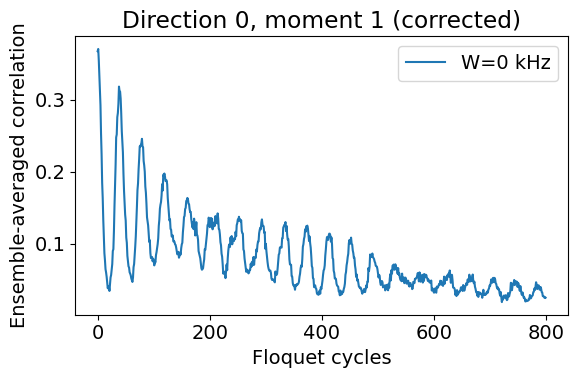

In [10]:
raw = False  # True selects uncorrected correlations.
suffix = "" if raw else "_corrected"
for direction, scan in disorder_scans.items():
    moments = (1, 2) if "C2" in scan.data else (1,)
    fig, axes = plt.subplots(1, len(moments), figsize=(6 * len(moments), 4),
                             sharex=True, squeeze=False)
    for axis, moment in zip(axes[0], moments):
        key = f"C{moment}"
        for part in scan.children:
            axis.plot(part.data["cycles"], part.data[key + suffix],
                      label=f"W={part.disorder_khz:g} kHz")
        axis.set(xlabel="Floquet cycles", ylabel="Ensemble-averaged correlation",
                 title=f"Direction {direction}, moment {moment} ({'raw' if raw else 'corrected'})")
        axis.legend()
    fig.tight_layout()
    plt.show()

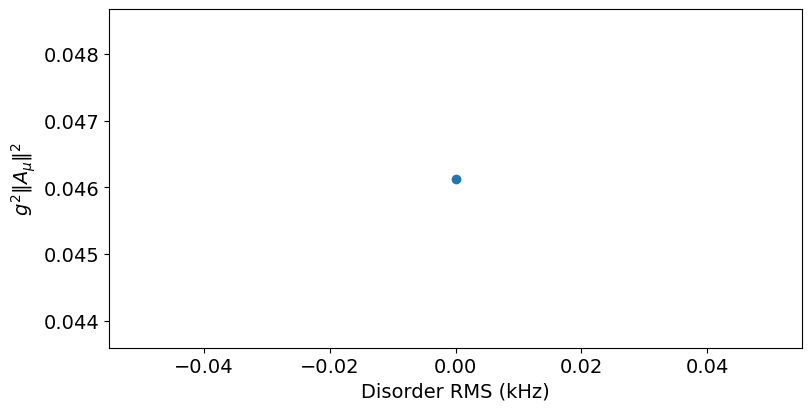

In [11]:
for scan in disorder_scans.values():
    scan.display()
    plt.show()

## 5. Save the assembled layers

Each direction has its own scan. save() writes each unsaved AGP part and then
the disorder scan under the experiment's assembled_data directory. Each layer
stores its arrays (including agp or agp_list) in HDF5 and a YAML manifest
pointing to the layer below. The used mu is stored beside each AGP value.
Shots remain in the original population JOB files.

Use from_h5file("path/to/scan.h5") for an arrays-only view, or
from_manifest("path/to/scan.yaml") to load the layers for reanalysis.

In [12]:
for direction, scan in disorder_scans.items():
    manifest_path = scan.save()
    print(f"Direction {direction}: {manifest_path}")

Direction 0: C:\experiments\agp_k44_first_scan\assembled_data\261024_003051_CentralBosonAGPDisorderScan.yaml


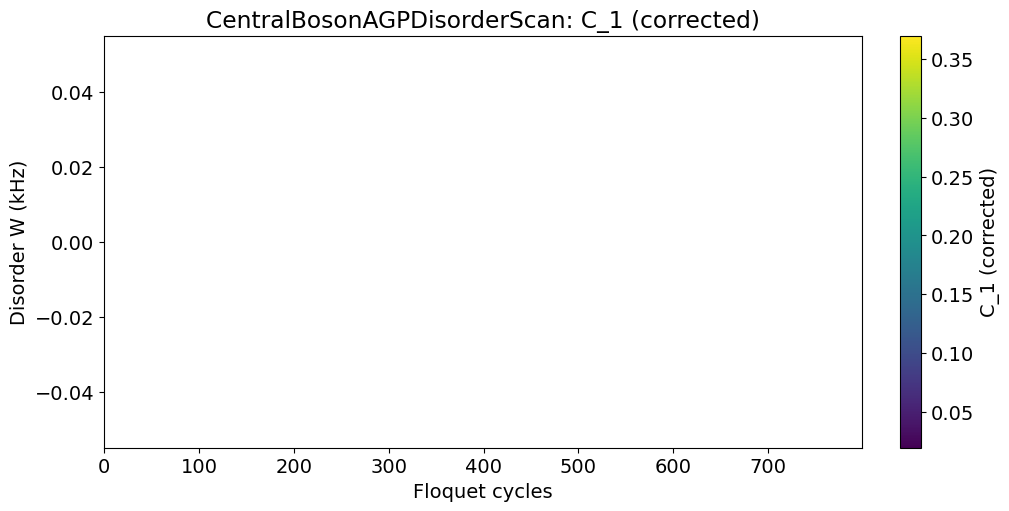

In [13]:
for scan in disorder_scans.values():
    moments = (1, 2) if "C2" in scan.data else (1,)
    for moment in moments:
        fig, axis = scan.display_correlation(moment=moment, raw=False)
        plt.show()
        plt.close(fig)